In [1]:
# =============================================
# IMPORT
# =============================================
from utility.logger         import aiLogger
from keras.callbacks        import EarlyStopping, ReduceLROnPlateau
from model.componentModel   import mainModel
from model.tepSystemModel   import SystemModel
from preProcessingDataTEP   import PreProcessData
# from prettytable            import PrettyTable

from keras.optimizers       import Adam
from utility.matpilotDraw   import MatPlot
from sklearn.preprocessing  import MinMaxScaler

import tensorflow           as tf
import pandas               as pd
import matplotlib.pyplot    as plt
import numpy                as np
import os, warnings
import random
import json



import sys
import shutil
import pathlib
import hashlib
import h5py
from tensorflow.keras import backend as K


2025-12-23 23:43:24.786573: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-12-23 23:43:26.295881: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
# ---------------------------
# Loading config file
# ---------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    configData = json.load(configFile)
config = configData["tep"]  

# ---------------------------
# Set debug level and 
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 
np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

outputDir               = os.path.expanduser(config["dataDir"])
totalTraject            = 100
normalizeHI             = True
showRedundantShutdown   = False

In [3]:
# ==============================
# Config and data preprocessing
# ==============================
preData             = PreProcessData(config=config)
rawData             = preData.loadDataFromH5Format(dir              = outputDir, 
                                                   name             = "data/teps.h5",
                                                   case             = "all", 
                                                   reduceSampleRate = True, 
                                                   removeHigherThr  = False)

withRULData         = preData.addRULAndEnvironment(rawData)

norData             = preData.normalizeDataEachModes(rawData    =  withRULData,
                                                     headline   =   preData.headline["allWithoutLabelNoBias"] + ["rul"])    # Normalize the data

Process:301774||2025-12-23 23:43:33,629-INFO [preProcessingDataTEP.py:loadDataFromH5Format():358]:Loading data from H5 files ...
Process:301774||2025-12-23 23:43:36,055-INFO [preProcessingDataTEP.py:loadDataFromH5Format():385]:Finish loading data from H5 files at case all...
Process:301774||2025-12-23 23:43:36,314-INFO [preProcessingDataTEP.py:addRULAndEnvironment():434]:Adding rul successfully...
Process:301774||2025-12-23 23:43:36,315-INFO [preProcessingDataTEP.py:normalizeDataEachModes():801]:Normalizing the data ...


In [7]:
# --- Robust import & load of your perturbed model weights (encoder + RUL only) ---

# HI_UPDATE_ROOT   = "./checkpoint/flCkpt/HI_model_update/"
# ORIGINALS_ROOT   = "./checkpoint/flCkpt/bestModel_5epoch/"
# TMP_MIRROR_ROOT  = "./checkpoint/flCkpt/_tmp_variant_mirror/"

# =============================================================================
# Project bootstrap
# =============================================================================
# PROJECT_ROOT = pathlib.Path("/content/drive/MyDrive/Duc_an_XAI_edge_cooperation")

# # Ensure 'kun' and 'kun/model' are proper Python packages
# for pkg_dir in [PROJECT_ROOT / "kun", PROJECT_ROOT / "kun" / "model"]:
#     pkg_dir.mkdir(parents=True, exist_ok=True)
#     (pkg_dir / "__init__.py").touch(exist_ok=True)

# # Put the project on sys.path
# path_str = str(PROJECT_ROOT.resolve())
# if path_str not in sys.path:
#     sys.path.insert(0, path_str)

# (Optional) clear TF session to avoid leftover graphs if you re-run this cell
K.clear_session()


# =============================================================================
# Helpers
# =============================================================================
def _comp_dir(root: str, sub: str, use_hi: bool) -> str:
    """Return the directory that holds numbered variants for a component."""
    return os.path.join(root, f"{sub}{'_HI_updates' if use_hi else ''}")

def _ensure_empty_dir(path: str):
    """Ensure a directory exists and is empty."""
    if os.path.isdir(path):
        shutil.rmtree(path)
    os.makedirs(path, exist_ok=True)

def _md5(path: str) -> str:
    """MD5 of the entire file (debug)."""
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def _first_float_stats(h5_path: str, max_items: int = 3):
    """
    Return up to 'max_items' (name, shape, mean, std) for float datasets in an HDF5 file.
    This gives you a quick fingerprint that should differ between original and perturbed variants.
    """
    out = []
    with h5py.File(h5_path, "r") as f:
        def visitor(n, o):
            if len(out) >= max_items:
                return
            if isinstance(o, h5py.Dataset) and np.issubdtype(o.dtype, np.floating):
                a = o[()]
                out.append((n, a.shape, float(a.mean()), float(a.std())))
        f.visititems(visitor)
    return out

def _print_h5_debug(label: str, path: str):
    """Print MD5 and a few dataset stats for quick verification."""
    print(f"[DEBUG] {label}: {path}")
    try:
        print(f"        MD5: { _md5(path) }")
        stats = _first_float_stats(path)
        if stats:
            for i, (n, shp, m, s) in enumerate(stats, 1):
                print(f"        ds#{i}: name={n}, shape={shp}, mean={m:.6f}, std={s:.6f}")
        else:
            print("        (no float datasets found)")
    except Exception as e:
        print(f"        (debug read failed: {e})")

def _copy_variant(src_dir: str, dst_dir: str, mapping_with_suffix: dict, idx: int, debug_compare_to: str = None):
    """
    Copy numbered variant files and rename them to expected standard names.
    Example mapping: {"encoderWts": "encoderWts"} will copy encoderWts_7.h5 -> encoderWts.h5
    """
    os.makedirs(dst_dir, exist_ok=True)
    for expected_name, base_stem in mapping_with_suffix.items():
        # Numbered variant (e.g., encoderWts_7.h5)
        src = os.path.join(src_dir, f"{base_stem}_{idx}.h5")
        dst = os.path.join(dst_dir, f"{expected_name}.h5")

        if not os.path.isfile(src):
            raise FileNotFoundError(f"Variant file not found: {src}")

        print(f"[COPY] {src}  ->  {dst}")
        shutil.copy2(src, dst)

        # Debug: compare to the original (if provided)
        if debug_compare_to is not None:
            orig = os.path.join(debug_compare_to, base_stem + ".h5")
            if os.path.isfile(orig):
                _print_h5_debug("ORIG ", orig)
            else:
                print(f"[DEBUG] ORIG not found (skipped): {orig}")
        _print_h5_debug("MIRROR", dst)  # show what we actually load afterwards


# =============================================================================
# Main function to load variant model
# =============================================================================
def load_variant_model(config, variant_idx=7, use_hi_updates=True):
    """
    Load a perturbed model variant with specified configuration.

    Args:
        config: Configuration dictionary containing model parameters
        variant_idx: Index of the variant to load (e.g., 7 for encoderWts_7.h5)
        use_hi_updates: Whether to use variants from "_HI_updates" folders

    Returns:
        vaeSys_contributor: Loaded SystemModel instance with variant weights
    """
    # =============================================================================
    # Variant selection
    # =============================================================================
    VARIANT_IDX = variant_idx
    USE_HI_UPDATES = use_hi_updates

    # Where your generated variants live (the destination from your perturbation script)
    VARIANTS_ROOT = "./checkpoint/flCkpt/HI_model_update/"

    # For sanity checks against originals (optional but recommended)
    ORIGINALS_ROOT = "./checkpoint/flCkpt/bestModel_5epoch/"

    # Temporary mirror: we will copy and rename numbered files here to the canonical names
    TMP_MIRROR_ROOT = "./checkpoint/flCkpt/_tmp_variant_mirror/"
    os.makedirs(TMP_MIRROR_ROOT, exist_ok=True)

    # =============================================================================
    # Source & destination directories (4 components)
    # =============================================================================
    SRC_REAC_DIR = _comp_dir(VARIANTS_ROOT, "bestModelReac", USE_HI_UPDATES)
    SRC_SEP_DIR = _comp_dir(VARIANTS_ROOT, "bestModelSep", USE_HI_UPDATES)
    SRC_STRIP_DIR = _comp_dir(VARIANTS_ROOT, "bestModelStrip", USE_HI_UPDATES)
    SRC_SYS_DIR = _comp_dir(VARIANTS_ROOT, "bestModelSys", USE_HI_UPDATES)

    DST_REAC_DIR = os.path.join(TMP_MIRROR_ROOT, "bestModelReac")
    DST_SEP_DIR = os.path.join(TMP_MIRROR_ROOT, "bestModelSep")
    DST_STRIP_DIR = os.path.join(TMP_MIRROR_ROOT, "bestModelStrip")
    DST_SYS_DIR = os.path.join(TMP_MIRROR_ROOT, "bestModelSys")

    # Rebuild mirror directories fresh
    _ensure_empty_dir(DST_REAC_DIR)
    _ensure_empty_dir(DST_SEP_DIR)
    _ensure_empty_dir(DST_STRIP_DIR)
    _ensure_empty_dir(DST_SYS_DIR)

    # Each component requires three files; system head needs the HI+RUL file
    COMP_MAPPING = {
        "encoderWts": "encoderWts",
        "decoderWts": "decoderWts",
        "maskWts": "maskWts",
    }
    SYS_MAPPING = {
        "hiAndRulWts": "hiAndRulWts",
    }

    print("=== Copying selected variants into the mirror (with debug fingerprints) ===")
    _copy_variant(SRC_REAC_DIR, DST_REAC_DIR, COMP_MAPPING, VARIANT_IDX,
                  debug_compare_to=os.path.join(ORIGINALS_ROOT, "bestModelReac"))
    _copy_variant(SRC_SEP_DIR, DST_SEP_DIR, COMP_MAPPING, VARIANT_IDX,
                  debug_compare_to=os.path.join(ORIGINALS_ROOT, "bestModelSep"))
    _copy_variant(SRC_STRIP_DIR, DST_STRIP_DIR, COMP_MAPPING, VARIANT_IDX,
                  debug_compare_to=os.path.join(ORIGINALS_ROOT, "bestModelStrip"))
    _copy_variant(SRC_SYS_DIR, DST_SYS_DIR, SYS_MAPPING, VARIANT_IDX,
                  debug_compare_to=os.path.join(ORIGINALS_ROOT, "bestModelSys"))

    print("\n=== Mirror is ready. About to build and load the model from the mirror ===\n")

    required_keys = ["seqLength", "inReac"]
    missing = [k for k in required_keys if k not in config]
    if missing:
        raise KeyError(f"Missing required config keys: {missing}")

    # Force System mode and ensure default HI selection dimension (adjust if your code differs)
    config["component"] = "Sys"
    config.setdefault("hiSelectionDim", 120)

    # The model should read weights from these subfolders when `freezeComponents` is True
    component_dir_root = TMP_MIRROR_ROOT

    # Instantiate your model
    vaeSys_contributor = SystemModel(config=config, componentModelPath=component_dir_root)

    # Build the model to initialize layers. This shape list must match your architecture.
    vaeSys_contributor.build(input_shape=[
        (None, config["seqLength"], config["inReac"]),  # main sequence
        (None, 1, config["inReac"]),                    # initial state
        (None, 1),                                      # scalar/time feature
        (None, config["hiSelectionDim"]),               # HI selection vector
    ])

    # Print the summary (optional but helpful)
    vaeSys_contributor.summary()

    # Prepare the canonical directories we just mirrored to
    modelDirComp1 = os.path.join(component_dir_root, "bestModelReac")
    modelDirComp2 = os.path.join(component_dir_root, "bestModelSep")
    modelDirComp3 = os.path.join(component_dir_root, "bestModelStrip")
    modelDirSys = os.path.join(component_dir_root, "bestModelSys")

    print("\n=== Loading weights from the MIRROR ===")
    print("Reac:  ", modelDirComp1)
    print("Sep:   ", modelDirComp2)
    print("Strip: ", modelDirComp3)
    print("Sys:   ", modelDirSys)
    vaeSys_contributor.load_weights(modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys)
    print("✓ Weights loaded from the selected variant ("
          f"idx={VARIANT_IDX}, HI_updates={USE_HI_UPDATES}).")

    return vaeSys_contributor


# =============================================================================
# Example usage / function call
# =============================================================================
if __name__ == "__main__":

    # Load the variant model
    # You can change variant_idx (0-9) and use_hi_updates (True/False) as needed
    vaeSys_contributor = load_variant_model(
        config=config,
        variant_idx=1,# We pertubte 10 different model,just choose any of them you want to see
        use_hi_updates=True
    )

    print("\n✅ Model loaded successfully and ready for use!")


=== Copying selected variants into the mirror (with debug fingerprints) ===
[COPY] ./checkpoint/flCkpt/HI_model_update/bestModelReac_HI_updates/encoderWts_1.h5  ->  ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelReac/encoderWts.h5
[DEBUG] ORIG : ./checkpoint/flCkpt/bestModel_5epoch/bestModelReac/encoderWts.h5
        MD5: 747c2c5715247558f61a5f9224347bfc
        (debug read failed: Unable to synchronously open file (file signature not found))
[DEBUG] MIRROR: ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelReac/encoderWts.h5
        MD5: 6cba90e92f9ce6ceb014b3c51913c7f1
        (debug read failed: Unable to synchronously open file (file signature not found))
[COPY] ./checkpoint/flCkpt/HI_model_update/bestModelReac_HI_updates/decoderWts_1.h5  ->  ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelReac/decoderWts.h5
[DEBUG] ORIG : ./checkpoint/flCkpt/bestModel_5epoch/bestModelReac/decoderWts.h5
        MD5: ffc64de1d4e3d0a44245ec6cc89b8ea6
        (debug read failed: Unable to synchronou

Process:301774||2025-12-23 23:45:37,024-DEBUG [tepSystemModel.py:__init__():317]:The shape of hiSelectionInput (None, 120)
Process:301774||2025-12-23 23:45:37,047-DEBUG [tepSystemModel.py:__init__():325]:The shape of multiplied matrix (None, 3)
Process:301774||2025-12-23 23:45:37,058-DEBUG [tepSystemModel.py:__init__():335]:The shape of min, max and linear HI ((None, 1), (None, 1), (None, 1))
Process:301774||2025-12-23 23:45:37,060-DEBUG [tepSystemModel.py:__init__():338]:The shape after concatenation (None, 3)
Process:301774||2025-12-23 23:45:37,062-DEBUG [tepSystemModel.py:__init__():341]:The shape after multiplying with mask (None, 3)
Process:301774||2025-12-23 23:45:37,068-DEBUG [tepSystemModel.py:__init__():345]:The shape of HI after reducing dimension (None, 1)


The shape of sysHILayer (None, 8, 5)
The shape of encLastDenseDim is 800
The shape of sysHILayer (None, 8, 5)
The shape of encLastDenseDim is 800
The shape of sysHILayer (None, 8, 5)
The shape of encLastDenseDim is 800


Model: "system_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sensor_selection                │ ?                      │   0 (unbuilt) │
│ (SensorSelection)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_selection_1              │ ?                      │   0 (unbuilt) │
│ (SensorSelection)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_selection_2              │ ?                      │   0 (unbuilt) │
│ (SensorSelection)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ ((None, 1), (None, 8,  │       103,906 │
│                                 │ 5))                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 45)        │       103,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ ((None, 1), (None, 8,  │       103,906 │
│                                 │ 5))                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 45)        │       103,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ ((None, 1), (None, 8,  │       103,906 │
│                                 │ 5))                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 45)        │       103,945 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hi_system_and_rul               │ ?                      │   0 (unbuilt) │
│ (HiSystemAndRul)                │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 636,842 (2.43 MB)

 Trainable params: 636,842 (2.43 MB)

 Non-trainable params: 0 (0.00 B)

Process:301774||2025-12-23 23:45:37,150-INFO [tepSystemModel.py:load_weights():896]:Loading the model at the direction: ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelReac, ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelSep, ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelStrip, ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelSys
Process:301774||2025-12-23 23:45:37,219-INFO [tepSystemModel.py:load_weights():928]:Loaded the model at the direction:./checkpoint/flCkpt/_tmp_variant_mirror/bestModelReac, ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelSep, ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelStrip, ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelSys successfully!!!



=== Loading weights from the MIRROR ===
Reac:   ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelReac
Sep:    ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelSep
Strip:  ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelStrip
Sys:    ./checkpoint/flCkpt/_tmp_variant_mirror/bestModelSys
✓ Weights loaded from the selected variant (idx=1, HI_updates=True).

✅ Model loaded successfully and ready for use!


#--------------------------------------------------------------------

In [8]:

environmentIdx      = 4
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime))

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,
                                                                shuffle     = False,
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys_contributor.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # aiLogger.debug(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

# aiLogger.debug((timeDraw[0].shape))
if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:301774||2025-12-23 23:45:41,486-INFO [preProcessingDataTEP.py:getTensorData():872]:Spliting data into sequences now ...


Getting the HI at the idx 1


Process:301774||2025-12-23 23:45:41,991-INFO [preProcessingDataTEP.py:getTensorData():872]:Spliting data into sequences now ...


Getting the HI at the idx 2


Process:301774||2025-12-23 23:45:42,499-INFO [preProcessingDataTEP.py:getTensorData():872]:Spliting data into sequences now ...


Getting the HI at the idx 3


... (190 outputs left out)

Process:301774||2025-12-23 23:46:34,683-INFO [preProcessingDataTEP.py:getTensorData():872]:Spliting data into sequences now ...


Getting the HI at the idx 99


Process:301774||2025-12-23 23:46:35,262-INFO [preProcessingDataTEP.py:getTensorData():872]:Spliting data into sequences now ...


Getting the HI at the idx 100


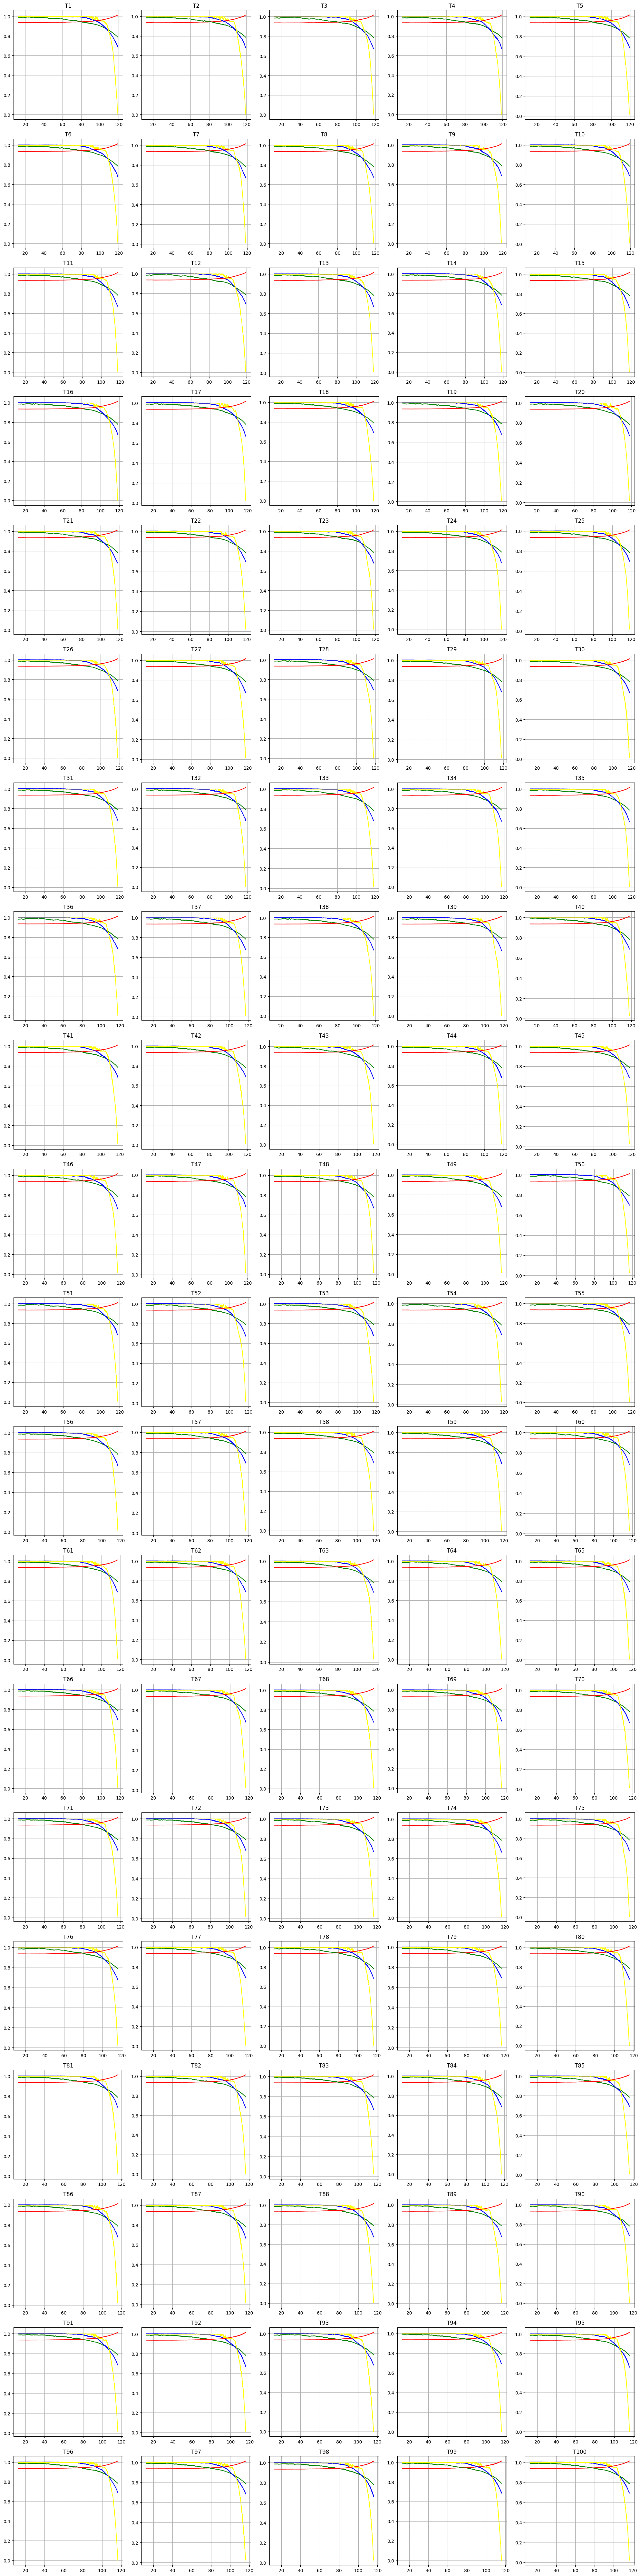

In [9]:

plot1 = MatPlot()
plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)